In [ ]:
import numpy as np
from methods.CoCaBO import CoCaBO


_F: dict = {
    0: lambda q1, q2, q3: -(q1 + 0.8)**2 - (q2 - 0.7)**2 - (q3 + 0.6)**2 + 2.5,
    1: lambda q1, q2, q3: -(q1 - 0.7)**2 - (q3 + 0.6)**2 - (q2 - 0.8)**2 + 0.5,
    2: lambda q1, q2, q3: -(q1 - 0.0)**2 - (q2 - 0.8)**2 - (q3 + 0.3)**2 + 0.2,
    3: lambda q1, q2, q3: -(q2 - 0.5)**2 - (q2 + 0.4)**2 - (q3 - 0.5)**2 + 0.3,
}

_G: dict = {
    0: lambda q1, q2, q3: -(q1 - 0.6)**2 - (q2 - 0.5)**2 - (q3 - 0.7)**2 + 2.0,
    1: lambda q1, q2, q3: -(q1 + 0.5)**2 - (q2 + 0.7)**2 - (q3 + 0.4)**2 + 0.3,
    2: lambda q1, q2, q3: -(q1 - 0.3)**2 - (q2 - 0.2)**2 - (q3 + 0.6)**2 + 0.1,
    3: lambda q1, q2, q3: -(q1 + 0.4)**2 - (q2 - 0.6)**2 - (q3 - 0.3)**2 + 0.0,
}

_SCALE_Q1: dict = {0: 2, 1: 2, 2: 1, 3: 1}
_SCALE_Q2: dict = {0: 2, 1: 2, 2: 1, 3: 1}


def objective_cocabo(
    ht: list[int],
    x: np.ndarray,
    sigma_noise: float = 0.0,
) -> np.ndarray:

    x = np.atleast_1d(x).flatten()
    qual1_idx: int = int(ht[0])
    qual2_idx: int = int(ht[1])
    q1: float = float(x[0])
    q2: float = float(x[1])
    q3: float = float(x[2])

    val: float = (
        _SCALE_Q1[qual1_idx] * _F[qual1_idx](q1, q2, q3)
        + _SCALE_Q2[qual2_idx] * _G[qual2_idx](q1, q2, q3)
    )

    if sigma_noise > 0.0:
        rng = np.random.default_rng()
        val += rng.normal(0.0, sigma_noise)

    return np.array([[-val]])



In [ ]:
BOUNDS: list[dict] = [
    {'name': 'qual1', 'type': 'categorical', 'domain': (0, 1, 2, 3)},
    {'name': 'qual2', 'type': 'categorical', 'domain': (0, 1, 2, 3)},
    {'name': 'quant1', 'type': 'continuous', 'domain': (-1.0, 1.0)},
    {'name': 'quant2', 'type': 'continuous', 'domain': (-1.0, 1.0)},
    {'name': 'quant3', 'type': 'continuous', 'domain': (-1.0, 1.0)},
]

# Nombre de modalites par variable categorielle.
# Doit correspondre a len(domain) pour chaque variable categorielle.
CATEGORIES: list[int] = [4, 4]

# Parametre kernel_mix : poids entre noyau produit et noyau somme.
# 0.0 = noyau somme pur (additif)
# 1.0 = noyau produit pur (multiplicatif)
# 0.5 = melange egal
# Le papier CoCaBO recommande d'optimiser ce parametre ou de le fixer a 0.5.
KERNEL_MIX: float = 1.0



In [ ]:
def run_cocabo(
    budget: int,
    n_init: int,
    kernel_mix: float,
    sigma_noise: float,
    seed: int,
) -> None:
    # La fonction objectif est fixee par closure sur sigma_noise
    def fn(ht: list[int], x: np.ndarray) -> np.ndarray:
        return objective_cocabo(ht, x, sigma_noise=sigma_noise)

    # Instanciation de CoCaBO
    # - objfn : la fonction objectif au format (ht, x) -> y de forme (1,1)
    # - initN : taille du DoE initial
    # - bounds : description des variables
    # - acq_type : 'LCB' (Lower Confidence Bound) ou 'EI'
    # - C : liste du nombre de modalites par variable categorielle
    # - kernel_mix : poids du melange de noyaux
    mabbo = CoCaBO(
        objfn=fn,
        initN=n_init,
        bounds=BOUNDS,
        acq_type='LCB',
        C=CATEGORIES,
        kernel_mix=kernel_mix,
    )
    mabbo.trial_num=0
    
    import os
    saving_path = 'data_init_cocabo.ignore/'
    os.makedirs(saving_path, exist_ok=True)
    mabbo.saving_path = saving_path

    # Lancement de l'optimisation pour un seul essai (trials=1).
    df = mabbo.runOptim(budget=budget, seed=seed, batch_size=1)

    # Affichage des resultats
    print("\n--- Resultats CoCaBO ---")
    print(df[["iter", "best_value"]].to_string(index=False))

    # Meilleur point trouve
    # CoCaBO stocke les donnees dans mabbo.data[0] (X) et mabbo.result[0] (Y)
    # Y est stocke avec le signe negatif (CoCaBO minimise), donc on prend -min
    best_y_cocabo: float = float(np.max(-1.0 * mabbo.result[0]))
    best_idx: int = int(np.argmin(mabbo.result[0]))
    best_x: np.ndarray = mabbo.data[0][best_idx]

    print(f"\nMeilleur y trouve : {best_y_cocabo:.4f}")
    print(f"Meilleur x trouve : {best_x}")
    print(f"  qual1={int(best_x[0])}, qual2={int(best_x[1])}")
    print(f"  quant1={best_x[2]:.4f}, quant2={best_x[3]:.4f}, quant3={best_x[4]:.4f}")

    return mabbo


Using existing init data for seed 100


  4%|▍         | 1/24 [00:00<00:10,  2.19it/s]

arm pulled=[0, 1]; y_best = 1.1545953017396835; mix=1.0


  8%|▊         | 2/24 [00:00<00:08,  2.52it/s]

arm pulled=[3, 2]; y_best = 1.1545953017396835; mix=1.0


...

arm pulled=[0, 3]; y_best = 4.041739754670417; mix=1.0


 96%|█████████▌| 23/24 [00:08<00:00,  2.47it/s]

arm pulled=[0, 3]; y_best = 4.177838434947041; mix=1.0


100%|██████████| 24/24 [00:08<00:00,  2.85it/s]

arm pulled=[1, 3]; y_best = 4.177838434947041; mix=1.0

--- Resultats CoCaBO ---
 iter  best_value
   -1   -0.011382
    0    1.154595
    1    1.154595
    2    1.154595
    3    1.154595
    4    1.154595
    5    2.780117
    6    2.780117
    7    2.780117
    8    2.780117
    9    2.780117
   10    4.041740
   11    4.041740
   12    4.041740
   13    4.041740
   14    4.041740
   15    4.041740
   16    4.041740
   17    4.041740
   18    4.041740
   19    4.041740
   20    4.041740
   21    4.041740
   22    4.177838
   23    4.177838

Meilleur y trouve : 4.1778
Meilleur x trouve : [ 0.          3.         -0.63317011  0.59231819 -0.45208278]
  qual1=0, qual2=3
  quant1=-0.6332, quant2=0.5923, quant3=-0.4521
Points totaux evalues : 40
  dont DoE initial    : 6
  dont iterations BO  : 34
Nombre de variables   : 5
    iter  qual1  qual2    quant1    quant2    quant3          y    best_y phase
0     -6      0      3  0.086810 -0.443261 -0.150965  -1.189473 -1.189473  init
1     -5

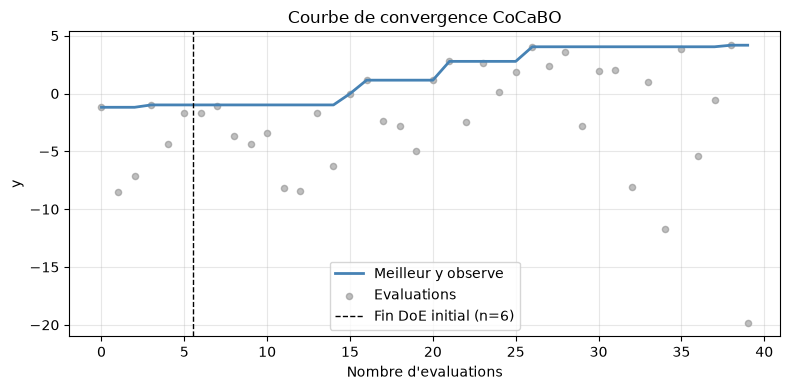

Graphique sauvegarde : convergence_cocabo.png


In [ ]:
# Budget total = n_init + budget iterations BO
BUDGET: int = 24         # nombre d'iterations BO apres le DoE initial
N_INIT: int = 6        # taille du DoE initial (CoCaBO choisit aleatoirement)
SIGMA_NOISE: float = 0.1
SEED: int = 100

if __name__ == '__main__':
    mabbo = run_cocabo(
        budget=BUDGET,
        n_init=N_INIT,
        kernel_mix=KERNEL_MIX,
        sigma_noise=SIGMA_NOISE,
        seed=SEED,
    )

    df, X_all, Y_all = extract_results(mabbo, trial=0)

    # Afficher le detail par iteration
    print(df.to_string())

    # Resume et top 5
    print_results(X_all, Y_all)

    # Courbe de convergence
    convergence_curve(Y_all, n_init=N_INIT)